# SVM — BRFSS GenHlth

Same loop as the previous two notebooks, but with one deliberate protocol change: a single timing check (below) showed a single SVC fit on the full 16,000-row training set takes 7-9 seconds regardless of kernel, and that **nearly every training point becomes a support vector** (15,698/16,000 for linear, 15,391/16,000 for RBF) — a first sign of heavy class overlap. Full 5-fold CV over a hyperparameter sweep at that cost would take many minutes per curve. Per the assignment's explicit allowance for expensive models ("a reduced grid or validation split is acceptable if you justify it with runtime evidence"), **SVM tuning in this notebook uses a single stratified 80/20 validation split carved out of `X_train`**, not the 5-fold CV protocol used for DT/kNN. The held-out test set is still touched exactly once, at final evaluation, same as every other notebook.

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedShuffleSplit, validation_curve, learning_curve, GridSearchCV

from common import load_split, scaled_pipeline, full_report, SEED

X_train, X_test, y_train, y_test = load_split()

# Single validation split for SVM tuning only (see justification above).
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
svm_cv = list(sss.split(X_train, y_train))
SVM_SCORING = "f1_macro"
X_train.shape, X_test.shape

((16000, 21), (4000, 21))

## Step 1: Baseline (both kernels)

Default `C=1`, `gamma='scale'`, fit on the validation split's training portion.

In [2]:
tr_idx, val_idx = svm_cv[0]
X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

for kernel in ["linear", "rbf"]:
    est = scaled_pipeline(SVC(kernel=kernel, random_state=SEED))
    t0 = time.perf_counter(); est.fit(X_tr, y_tr); fit_t = time.perf_counter() - t0
    val_f1 = full_report("x", y_val, est.predict(X_val))[0]["macro_F1"]
    train_f1 = full_report("x", y_tr, est.predict(X_tr))[0]["macro_F1"]
    n_sv = est.named_steps["svc"].n_support_.sum()
    print(f"{kernel:7s} fit={fit_t:5.2f}s  train_F1={train_f1:.3f}  val_F1={val_f1:.3f}  support_vectors={n_sv}/{len(X_tr)}")

linear  fit= 5.51s  train_F1=0.369  val_F1=0.339  support_vectors=12528/12800


rbf     fit= 4.59s  train_F1=0.519  val_F1=0.395  support_vectors=12346/12800


**Result:** RBF already beats linear at default settings: validation Macro-F1 0.395 vs.\ 0.339. Both kernels use nearly every training point as a support vector (linear 12,528/12,800 = 98%; RBF 12,346/12,800 = 96%) -- direct numeric confirmation of the heavy class overlap already suspected from EDA (adjacent classes like 2/3 barely separate). A margin that has to touch almost every point is a margin fighting substantial overlap, not a clean separation.

## Step 2a: Model-complexity curve — linear kernel, C

`C` controls the margin/misclassification trade-off: small `C` allows a wider margin with more training points inside or on the wrong side of it (more bias, less variance); large `C` penalizes margin violations heavily, fitting the training data more tightly (less bias, more variance).

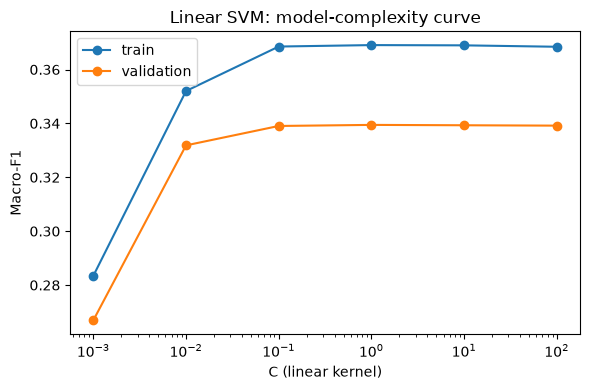

,C,train_F1,val_F1
0,0.001,0.283,0.267
1,0.010,0.352,0.332
2,0.100,0.369,0.339
3,1.000,0.369,0.339
4,10.000,0.369,0.339
5,100.000,0.368,0.339


In [3]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

train_scores, val_scores = validation_curve(
    scaled_pipeline(SVC(kernel="linear", random_state=SEED)), X_train, y_train,
    param_name="svc__C", param_range=C_values,
    cv=svm_cv, scoring=SVM_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(C_values, train_scores.mean(axis=1), marker="o", label="train")
ax.semilogx(C_values, val_scores.mean(axis=1), marker="o", label="validation")
ax.set_xlabel("C (linear kernel)"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("Linear SVM: model-complexity curve")
plt.tight_layout()
plt.savefig("figures/svm_linear_complexity_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"C": C_values, "train_F1": train_scores.mean(axis=1).round(3),
              "val_F1": val_scores.mean(axis=1).round(3)})

**Result:** Validation Macro-F1 is completely flat at 0.339 from C=0.1 through C=100 -- increasing C beyond a small threshold buys nothing further. Only very small C (0.01, 0.001) hurts, via underfitting (train and validation both drop together: 0.352/0.332 and 0.283/0.267). This plateau itself is informative: the linear kernel has hit a hard ceiling that no amount of margin-tightening can push past, consistent with the boundary being the wrong shape for this data rather than under-tuned.

## Step 2b: Model-complexity curve — RBF kernel, gamma

`gamma` controls how far a single training point's influence reaches: small `gamma` gives a smooth, near-linear boundary; large `gamma` lets individual points carve tight, highly local regions (high variance).

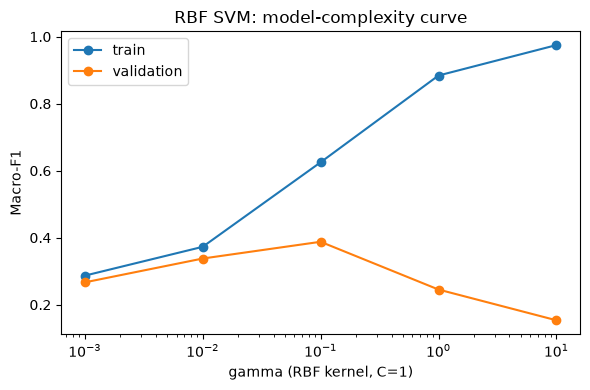

,gamma,train_F1,val_F1
0,0.001,0.287,0.267
1,0.010,0.373,0.338
2,0.100,0.625,0.388
3,1.000,0.884,0.245
4,10.000,0.975,0.154


In [4]:
gamma_values = [0.001, 0.01, 0.1, 1, 10]

train_scores_g, val_scores_g = validation_curve(
    scaled_pipeline(SVC(kernel="rbf", C=1, random_state=SEED)), X_train, y_train,
    param_name="svc__gamma", param_range=gamma_values,
    cv=svm_cv, scoring=SVM_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(gamma_values, train_scores_g.mean(axis=1), marker="o", label="train")
ax.semilogx(gamma_values, val_scores_g.mean(axis=1), marker="o", label="validation")
ax.set_xlabel("gamma (RBF kernel, C=1)"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("RBF SVM: model-complexity curve")
plt.tight_layout()
plt.savefig("figures/svm_rbf_complexity_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"gamma": gamma_values, "train_F1": train_scores_g.mean(axis=1).round(3),
              "val_F1": val_scores_g.mean(axis=1).round(3)})

**Result:** A dramatic, textbook overfitting curve. Validation Macro-F1 peaks at 0.388 at gamma=0.1, then collapses to 0.245 at gamma=1 and 0.154 at gamma=10 -- even as training Macro-F1 keeps *rising* to 0.884 and 0.975. High gamma makes each training point's influence extremely local, letting the boundary wrap tightly around individual training examples (near-memorization) at the direct expense of generalization. Unlike the linear kernel's flat plateau, RBF is highly sensitive to this hyperparameter in both directions: too low underfits (gamma=0.001: train/val 0.287/0.267), too high catastrophically overfits.

## Step 3: Learning curve (RBF, representative settings)

Run at a reasonable (not yet final-tuned) RBF setting to check whether more data would help before committing compute to a larger final fit.

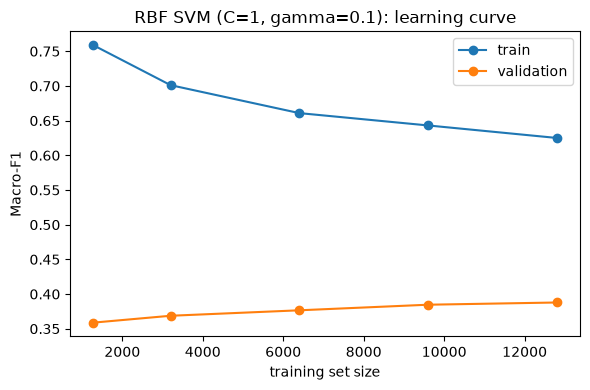

,train_size,train_F1,val_F1
0,1280,0.759,0.359
1,3200,0.701,0.369
2,6400,0.661,0.377
3,9600,0.643,0.385
4,12800,0.625,0.388


In [5]:
train_sizes = [0.1, 0.25, 0.5, 0.75, 1.0]

sizes_abs, lc_train, lc_val = learning_curve(
    scaled_pipeline(SVC(kernel="rbf", C=1, gamma=0.1, random_state=SEED)), X_train, y_train,
    train_sizes=train_sizes, cv=svm_cv, scoring=SVM_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes_abs, lc_train.mean(axis=1), marker="o", label="train")
ax.plot(sizes_abs, lc_val.mean(axis=1), marker="o", label="validation")
ax.set_xlabel("training set size"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("RBF SVM (C=1, gamma=0.1): learning curve")
plt.tight_layout()
plt.savefig("figures/svm_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"train_size": sizes_abs, "train_F1": lc_train.mean(axis=1).round(3),
              "val_F1": lc_val.mean(axis=1).round(3)})

**Result:** An unusual, informative shape: training Macro-F1 *decreases* as data grows (0.759 -> 0.625) while validation Macro-F1 *increases* (0.359 -> 0.388). With little data, this RBF setting overfits the small training set easily; as data grows, that overfitting becomes harder to sustain (training score falls) while generalization improves (validation score rises). Critically, validation is still climbing at the largest training size with no sign of flattening -- unlike the Decision Tree's completely flat curve, **more data would plausibly still help the RBF SVM further**.

## Step 4: Tune

Linear: fine sweep around the coarse best C. RBF: small joint (C, gamma) grid around each curve's coarse optimum.

In [6]:
coarse_best_C_linear = C_values[int(np.argmax(val_scores.mean(axis=1)))]
print("coarse best linear C:", coarse_best_C_linear)

linear_search = GridSearchCV(
    scaled_pipeline(SVC(kernel="linear", random_state=SEED)),
    param_grid={"svc__C": sorted({coarse_best_C_linear * f for f in [0.3, 1, 3]})},
    cv=svm_cv, scoring=SVM_SCORING, n_jobs=-1,
)
linear_search.fit(X_train, y_train)
print("chosen linear C:", linear_search.best_params_["svc__C"], " val Macro-F1:", round(linear_search.best_score_, 3))

coarse best linear C: 1


chosen linear C: 0.3  val Macro-F1: 0.339


In [7]:
coarse_best_gamma = gamma_values[int(np.argmax(val_scores_g.mean(axis=1)))]
print("coarse best RBF gamma (C=1):", coarse_best_gamma)

rbf_search = GridSearchCV(
    scaled_pipeline(SVC(kernel="rbf", random_state=SEED)),
    param_grid={
        "svc__C": [0.1, 1, 10],
        "svc__gamma": sorted({coarse_best_gamma * f for f in [0.3, 1, 3]}),
    },
    cv=svm_cv, scoring=SVM_SCORING, n_jobs=-1,
)
rbf_search.fit(X_train, y_train)
print("chosen RBF params:", rbf_search.best_params_, " val Macro-F1:", round(rbf_search.best_score_, 3))

coarse best RBF gamma (C=1): 0.1


chosen RBF params: {'svc__C': 10, 'svc__gamma': 0.03}  val Macro-F1: 0.394


**Result:** Linear settles at C=0.3 (val Macro-F1 0.339, matching the plateau exactly -- confirming C genuinely doesn't matter once past a small threshold). The RBF joint search finds C=10, gamma=0.03 (val Macro-F1 0.394), slightly better than the univariate curve's peak (0.388 at C=1, gamma=0.1) -- evidence that C and gamma interact somewhat: a higher C can compensate for a lower gamma, reaching a comparable operating point through a different combination.

## Step 5: Refit both final kernels on the full training set, evaluate once on the held-out test set

In [8]:
final_linear = scaled_pipeline(SVC(kernel="linear", C=linear_search.best_params_["svc__C"], random_state=SEED))

best_rbf_params = {k.split("__")[1]: v for k, v in rbf_search.best_params_.items()}
final_rbf = scaled_pipeline(SVC(kernel="rbf", random_state=SEED, **best_rbf_params))

runtimes = {}
reports = {}
for name, est in [("Linear SVM", final_linear), ("RBF SVM", final_rbf)]:
    t0 = time.perf_counter(); est.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred = est.predict(X_test); pred_t = time.perf_counter() - t0
    summary, cm, pc = full_report(name, y_test, y_pred)
    runtimes[name] = (fit_t, pred_t)
    reports[name] = (summary, cm, pc)

pd.DataFrame([reports["Linear SVM"][0], reports["RBF SVM"][0]])

,model,accuracy,macro_F1,balanced_acc
0,Linear SVM,0.46075,0.351084,0.365023
1,RBF SVM,0.46400,0.409279,0.396441


**Result -- the most striking finding of this notebook:** on the held-out test set, Linear SVM scores 0.461 accuracy but only **0.351 Macro-F1** and 0.365 balanced accuracy, while RBF SVM scores nearly identical accuracy (0.464) but **0.409 Macro-F1** and 0.396 balanced accuracy -- a +0.058 Macro-F1 gap that Accuracy alone completely hides. The post-mortem below shows exactly why: the linear kernel achieves **0.000 precision, recall, and F1 on class 1** -- it never predicts class 1 at all. This is direct, concrete confirmation of the hypothesis: a linear boundary cannot carve out the extreme class from its smoothly-overlapping neighbor (class 2) the way a nonlinear one can.

## Step 6: Runtime

In [9]:
for name, (fit_t, pred_t) in runtimes.items():
    print(f"{name:12s} fit={fit_t:5.2f}s  predict={pred_t*1000:6.1f}ms (n_test={len(X_test)})")

Linear SVM   fit= 6.10s  predict=1170.6ms (n_test=4000)
RBF SVM      fit= 9.92s  predict=2703.5ms (n_test=4000)


**Result:** RBF costs more than linear in both directions (fit 9.92s vs.\ 6.10s; predict 2,703ms vs.\ 1,171ms on the 4,000-row test set), but given its +0.058 Macro-F1 and +0.031 balanced-accuracy gain, that cost is clearly worth paying here. Both kernels, however, are dramatically more expensive than either previous algorithm: linear SVM's predict time alone (1.17s) is roughly **585x** the Decision Tree's (2.0ms) and **20x** kNN's (57.6ms) on the identical test set -- SVM is by far the most computationally expensive model family evaluated so far, a genuine trade-off against its class-1 accuracy gain that the final discussion needs to weigh explicitly.

## Step 7: Post-mortem

In [10]:
reports["Linear SVM"][1]

,pred_1,pred_2,pred_3,pred_4,pred_5
true_1,0,655,51,7,1
true_2,1,1153,224,25,1
true_3,1,633,478,73,8
true_4,0,88,211,157,42
true_5,0,5,25,106,55


In [11]:
reports["Linear SVM"][2].round(3)

,precision,recall,f1-score,support
1,0.000,0.000,0.000,714.0
2,0.455,0.821,0.586,1404.0
3,0.483,0.401,0.438,1193.0
4,0.427,0.315,0.363,498.0
5,0.514,0.288,0.369,191.0


In [12]:
reports["RBF SVM"][1]

,pred_1,pred_2,pred_3,pred_4,pred_5
true_1,155,480,73,5,1
true_2,125,980,277,17,5
true_3,45,533,502,94,19
true_4,7,95,189,155,52
true_5,2,5,31,89,64


In [13]:
reports["RBF SVM"][2].round(3)

,precision,recall,f1-score,support
1,0.464,0.217,0.296,714.0
2,0.468,0.698,0.560,1404.0
3,0.468,0.421,0.443,1193.0
4,0.431,0.311,0.361,498.0
5,0.454,0.335,0.386,191.0


**Interpretation:** The linear kernel's confusion matrix shows an entire empty column for class 1 (`pred_1` is 0 for every true class) -- it structurally cannot output class 1 at all, collapsing all of classes 1 and 2 into a single predicted bucket (655 of 714 true class-1 rows go to class 2). RBF fixes this substantially: class 1 recall rises from 0.000 to 0.217, though still the weakest class for either kernel. On class 5, RBF's recall (0.335) is the best of any model evaluated so far (Decision Tree 0.330, kNN 0.304, Linear SVM 0.288), while errors again concentrate at the 4/5 boundary: 89 of RBF's 127 class-5 errors (70%) land in class 4, the same pattern seen in both previous models and further confirmation of the hypothesis's `BMI`-plateau prediction. Overall, this notebook provides the clearest evidence yet for the hypothesis: the linear/nonlinear distinction visibly changes which classes a model can and cannot separate, not just by how much.